# Eksploracyjna analiza danych Wikipedii

Notebook analizuje pliki JSON z `data/raw/wikipedia/`. Dane zawierają historię rewizji stron Wikipedii pobraną przez scraper projektu.

Codebook (`codebook/codebook.yaml`) i instrument v1 (`src/digital_media_analysis/instruments/rules_v1.py`) są wspólne z notebookiem Reddita.

In [1]:
import json
import re
from urllib.parse import unquote

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

from digital_media_analysis.paths import RAW_WIKIPEDIA_DIR

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = RAW_WIKIPEDIA_DIR
files = sorted(DATA_DIR.glob("*.json"))
if not files:
    raise FileNotFoundError(f"Nie znaleziono plików JSON w {DATA_DIR}")

len(files), [file.name for file in files]

(8,
 ['COVID-19.json',
  'Globalne_ocieplenie.json',
  'Kwas_askorbinowy.json',
  'Lekarz.json',
  'Medycyna.json',
  'Szczepionka.json',
  'Zespół_nabytego_niedoboru_odporności.json',
  'Zmiana_klimatu.json'])

## Wczytanie i normalizacja danych

Każdy rekord odpowiada jednej rewizji. Z treści rewizji wyliczamy cechy ilościowe, aby dalsza analiza nie musiała wielokrotnie przetwarzać dużych pól tekstowych.

In [2]:
records = []
page_summary = []

for path in files:
    with path.open(encoding="utf-8") as file:
        payload = json.load(file)

    url = payload.get("url")
    edits = payload.get("edits", [])
    page_title = unquote(url.rsplit("/", 1)[-1]) if url else path.stem
    page_title = page_title.replace("_", " ")

    for edit_number, edit in enumerate(edits, start=1):
        content = edit.get("new_content") or ""
        records.append({
            "page": page_title,
            "url": url,
            "revision_number": edit_number,
            "introduced": edit.get("introduced"),
            "comment_field_present": "comment" in edit,
            "comment": edit.get("comment", ""),
            "content_chars": len(content),
            "content_lines": content.count("\n") + (1 if content else 0),
            "content_words": len(re.findall(r"\b\w+\b", content, flags=re.UNICODE)),
            "links": len(re.findall(r"\[\[.*?\]\]", content, flags=re.DOTALL)),
            "templates": len(re.findall(r"\{\{.*?\}\}", content, flags=re.DOTALL)),
        })

    page_summary.append({
        "page": page_title,
        "url": url,
        "revisions": len(edits),
        "file_mb": path.stat().st_size / 1024**2,
    })

df = pd.DataFrame(records)
df["introduced"] = pd.to_datetime(df["introduced"], utc=True, errors="coerce")
df["comment"] = df["comment"].fillna("").astype(str).str.strip()
df["year"] = df["introduced"].dt.year
df["month"] = df["introduced"].dt.tz_convert(None).dt.to_period("M").astype("string")
pages = pd.DataFrame(page_summary).sort_values("revisions", ascending=False)
df.head()

,page,url,revision_number,introduced,comment_field_present,comment,content_chars,content_lines,content_words,links,templates,year,month
0,COVID-19,https://pl.wikipedia.org/wiki/COVID-19,1,2020-02-12 08:35:29+00:00,True,COVID-19 start,5562,75,729,19,16,2020,2020-02
1,COVID-19,https://pl.wikipedia.org/wiki/COVID-19,2,2020-02-12 08:37:22+00:00,True,d,5816,75,774,19,17,2020,2020-02
2,COVID-19,https://pl.wikipedia.org/wiki/COVID-19,3,2020-02-12 14:52:23+00:00,True,"[[WP:SK]], drobne techniczne",5809,74,772,19,17,2020,2020-02
3,COVID-19,https://pl.wikipedia.org/wiki/COVID-19,4,2020-02-12 20:32:49+00:00,True,kat.,5835,74,774,20,17,2020,2020-02
4,COVID-19,https://pl.wikipedia.org/wiki/COVID-19,5,2020-02-13 08:29:40+00:00,True,"akt., drobne redakcyjne",5867,74,779,20,17,2020,2020-02


## Rozmiar zbioru i kontrola jakości

In [3]:
quality = pd.Series({
    "liczba plików / stron": len(files),
    "liczba rewizji": len(df),
    "najwcześniejsza rewizja": df["introduced"].min(),
    "najpóźniejsza rewizja": df["introduced"].max(),
    "brakujące daty": int(df["introduced"].isna().sum()),
    "puste treści": int((df["content_chars"] == 0).sum()),
})
display(quality.to_frame("wartość"))
display(pages)
display(df.isna().sum().to_frame("braki"))

,wartość
liczba plików / stron,8
liczba rewizji,2222
najwcześniejsza rewizja,2016-01-10 14:24:04+00:00
najpóźniejsza rewizja,2026-10-13 15:02:41+00:00
brakujące daty,0
puste treści,6


,page,url,revisions,file_mb
0,COVID-19,https://pl.wikipedia.org/wiki/COVID-19,853,55.709651
6,Zespół nabytego niedoboru odporności,https://pl.wikipedia.org/wiki/Zesp%C3%B3%C5%82_nabytego_niedoboru_odporno%C5%9Bci,320,71.973558
5,Szczepionka,https://pl.wikipedia.org/wiki/Szczepionka,299,19.532502
1,Globalne ocieplenie,https://pl.wikipedia.org/wiki/Globalne_ocieplenie,279,32.140097
3,Lekarz,https://pl.wikipedia.org/wiki/Lekarz,197,4.585526
2,Kwas askorbinowy,https://pl.wikipedia.org/wiki/Kwas_askorbinowy,151,6.069566
7,Zmiana klimatu,https://pl.wikipedia.org/wiki/Zmiana_klimatu,75,1.799268
4,Medycyna,https://pl.wikipedia.org/wiki/Medycyna,48,0.309065


,braki
page,0
url,0
revision_number,0
introduced,0
comment_field_present,0
comment,0
content_chars,0
content_lines,0
content_words,0
links,0


## Porównanie stron

Liczba rewizji jest przybliżeniem aktywności edycyjnej w zakresie dat pobranym przez scraper. Rozmiar treści opisuje stan strony w poszczególnych rewizjach, a nie rozmiar pojedynczej zmiany.

,page,revisions,mean_chars,median_chars,max_chars,mean_links
0,COVID-19,853,66215.0,73537.0,102471,122.3
6,Zespół nabytego niedoboru odporności,320,226905.0,257011.0,264006,499.0
5,Szczepionka,299,65724.0,68384.0,85770,178.7
1,Globalne ocieplenie,279,116550.0,117039.0,129597,311.7
3,Lekarz,197,23174.0,21876.0,33459,262.5
2,Kwas askorbinowy,151,40324.0,42785.0,49461,186.3
7,Zmiana klimatu,75,23897.0,23367.0,28591,94.9
4,Medycyna,48,6291.0,6306.0,6429,140.5


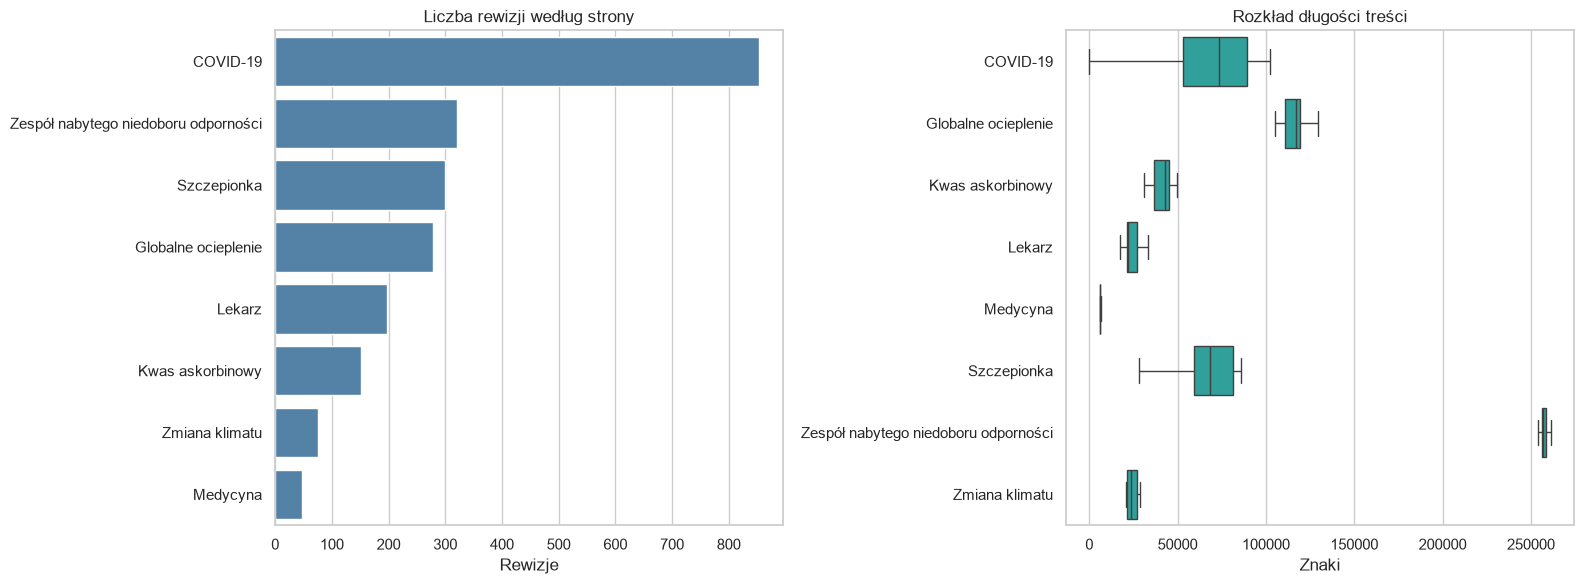

In [4]:
page_metrics = (
    df.groupby("page", as_index=False)
      .agg(
          revisions=("page", "size"),
          mean_chars=("content_chars", "mean"),
          median_chars=("content_chars", "median"),
          max_chars=("content_chars", "max"),
          mean_links=("links", "mean"),
      )
      .sort_values("revisions", ascending=False)
)
display(page_metrics.round({"mean_chars": 0, "median_chars": 0, "max_chars": 0, "mean_links": 1}))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=page_metrics, y="page", x="revisions", ax=axes[0], color="steelblue")
axes[0].set(title="Liczba rewizji według strony", xlabel="Rewizje", ylabel="")
sns.boxplot(data=df, y="page", x="content_chars", ax=axes[1], color="lightseagreen", showfliers=False)
axes[1].set(title="Rozkład długości treści", xlabel="Znaki", ylabel="")
plt.tight_layout()

## Aktywność w czasie

page,COVID-19,Globalne ocieplenie,Kwas askorbinowy,Lekarz,Medycyna,Szczepionka,Zespół nabytego niedoboru odporności,Zmiana klimatu
introduced,,,,,,,,
2016-12-31 00:00:00+00:00,0,12,33,21,6,9,28,1
2017-12-31 00:00:00+00:00,0,9,21,11,3,90,50,2
2018-12-31 00:00:00+00:00,0,48,35,10,7,37,32,10
2019-12-31 00:00:00+00:00,0,26,8,17,4,66,20,10
2020-12-31 00:00:00+00:00,619,43,13,25,1,25,85,12
2021-12-31 00:00:00+00:00,141,36,5,32,13,33,22,12
2022-12-31 00:00:00+00:00,52,37,6,20,5,11,8,9
2023-12-31 00:00:00+00:00,11,24,0,18,4,10,11,3
2024-12-31 00:00:00+00:00,13,21,16,22,2,6,43,2


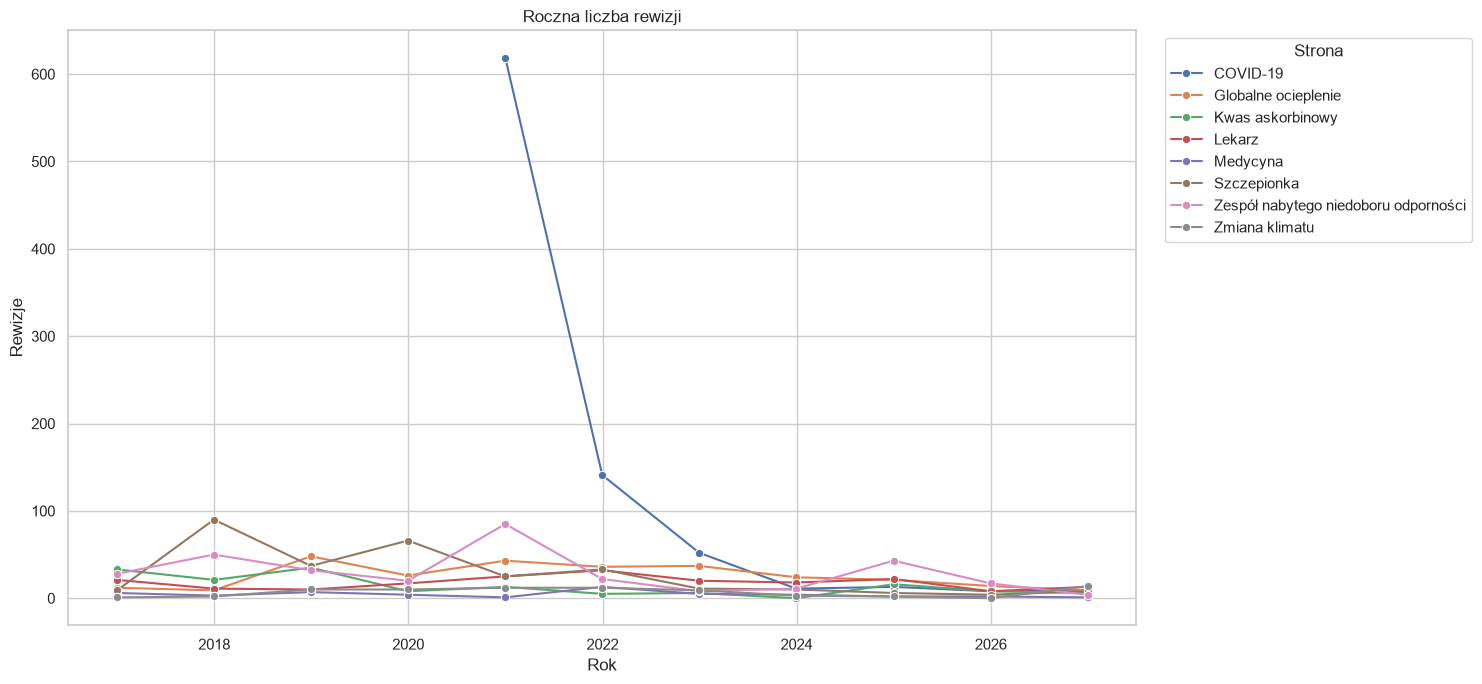

In [5]:
activity = (
    df.dropna(subset=["introduced"])
      .set_index("introduced")
      .groupby("page")
      .resample("YE")
      .size()
      .rename("revisions")
      .reset_index()
)

plt.figure(figsize=(15, 7))
sns.lineplot(data=activity, x="introduced", y="revisions", hue="page", marker="o")
plt.title("Roczna liczba rewizji")
plt.xlabel("Rok")
plt.ylabel("Rewizje")
plt.legend(title="Strona", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

display(activity.pivot(index="introduced", columns="page", values="revisions").fillna(0).astype(int))

## Zależności między cechami rewizji

Macierz korelacji pokazuje, czy większe treści mają zwykle więcej linków lub szablonów. Korelacja nie oznacza związku przyczynowego.

,count,mean,std,min,25%,50%,75%,95%,max
content_chars,2222.0,87312.542754,71464.953350,0.0,39358.00,72214.0,102102.00,257761.00,264006.0
content_lines,2222.0,372.435644,275.895871,0.0,234.00,317.0,422.75,724.00,1757.0
content_words,2222.0,11885.382988,9510.176134,0.0,5337.25,10332.0,14485.00,34002.95,35323.0
links,2222.0,224.198920,145.966706,0.0,129.00,166.5,289.00,563.00,583.0
templates,2222.0,197.022952,180.652467,0.0,79.00,174.0,196.00,647.00,680.0


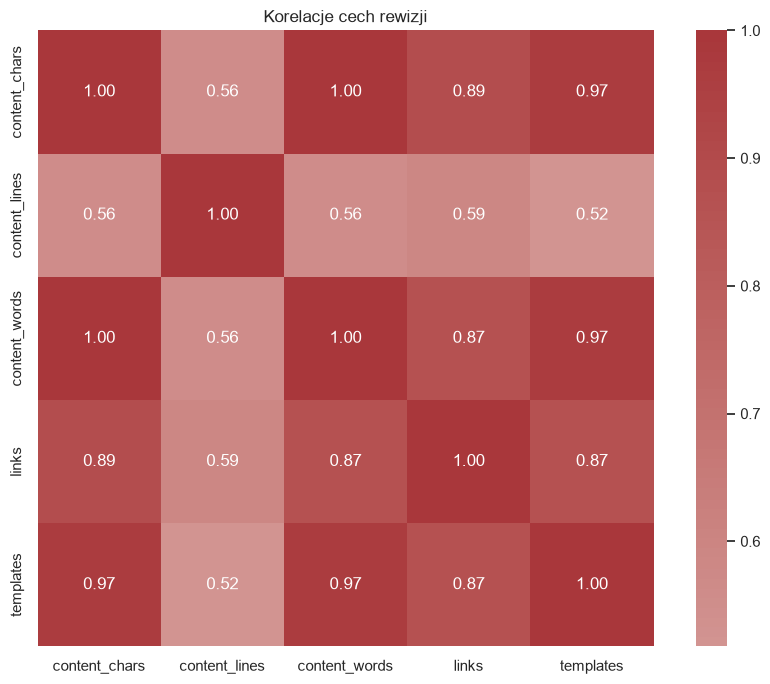

In [6]:
numeric_columns = ["content_chars", "content_lines", "content_words", "links", "templates"]
corr = df[numeric_columns].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Korelacje cech rewizji")
plt.tight_layout()

display(df[numeric_columns].describe(percentiles=[.25, .5, .75, .95]).T)

## Największe obserwowane wersje stron

Poniższa tabela pomaga zidentyfikować rewizje o największej objętości tekstu i potencjalne obserwacje odstające.

In [7]:
largest_revisions = (
    df.nlargest(15, "content_chars")
      [["page", "introduced", "revision_number", "content_chars", "content_words", "links", "templates"]]
      .reset_index(drop=True)
)
display(largest_revisions.round({"content_chars": 0, "content_words": 0}))

,page,introduced,revision_number,content_chars,content_words,links,templates
0,Zespół nabytego niedoboru odporności,2025-06-28 11:13:37+00:00,309,264006,35323,577,680
1,Zespół nabytego niedoboru odporności,2025-06-28 11:11:34+00:00,308,263987,35322,576,680
2,Zespół nabytego niedoboru odporności,2025-06-28 11:02:38+00:00,307,263915,35310,576,679
3,Zespół nabytego niedoboru odporności,2025-06-28 11:00:14+00:00,306,263849,35302,575,678
4,Zespół nabytego niedoboru odporności,2025-10-19 11:33:06+00:00,314,263712,35272,578,678
5,Zespół nabytego niedoboru odporności,2025-06-27 23:14:51+00:00,305,263701,35287,568,678
6,Zespół nabytego niedoboru odporności,2026-03-12 15:32:16+00:00,318,263663,35263,578,677
7,Zespół nabytego niedoboru odporności,2026-01-09 13:32:56+00:00,317,263650,35263,578,677
8,Zespół nabytego niedoboru odporności,2025-09-01 21:32:49+00:00,313,263649,35263,578,677
9,Zespół nabytego niedoboru odporności,2025-10-19 12:06:29+00:00,315,263649,35263,578,677


## Wnioski do dalszej analizy

- Porównaj aktywność stron z tematyką i wydarzeniami zewnętrznymi.
- Do analizy zmian między rewizjami oblicz różnice tekstowe, zamiast porównywać tylko długości.
- Sprawdź obserwacje odstające przed modelowaniem, ponieważ strony różnią się skalą i liczbą rewizji.
- Jeśli potrzebne są statystyki autorów, scraper musi zapisywać dodatkowo identyfikator użytkownika rewizji.

## Analiza komentarzy (opisów zmian)

Wikipedia przechowuje komentarz redaktora przy każdej rewizji. Jest to krótki opis wykonanej zmiany, a nie komentarz dyskusyjny z karty „Dyskusja”. Sekcja analizuje pokrycie komentarzami, ich długość, aktywność w czasie oraz najczęstsze słowa. Aby uzyskać kompletne wyniki, pobierz dane ponownie po aktualizacji scrapera.

In [8]:
if "comment" not in df.columns:
    raise ValueError(
        "Brak kolumny 'comment'. Uruchom ponownie pobieranie danych Wikipedii "
        "po aktualizacji scrapera."
    )

df["comment"] = df["comment"].fillna("").astype(str).str.strip()
df["has_comment"] = df["comment"].ne("")
df["comment_chars"] = df["comment"].str.len()
df["comment_words"] = df["comment"].str.findall(r"\b\w+\b").str.len()

comment_quality = pd.Series({
    "rewizje ogółem": len(df),
    "rewizje z polem comment": int(df["comment_field_present"].sum()),
    "brak pola comment": int((~df["comment_field_present"]).sum()),
    "rewizje z komentarzem": int(df["has_comment"].sum()),
    "odsetek rewizji z komentarzem (%)": 100 * df["has_comment"].mean(),
    "mediana znaków komentarza": df.loc[df["has_comment"], "comment_chars"].median(),
    "mediana słów komentarza": df.loc[df["has_comment"], "comment_words"].median(),
})
display(comment_quality.to_frame("wartość").round(1))

comment_by_page = (
    df.groupby("page", as_index=False)
      .agg(
          revisions=("revision_number", "size"),
          comments=("has_comment", "sum"),
          comment_rate=("has_comment", "mean"),
          median_comment_chars=("comment_chars", lambda values: values[values > 0].median()),
      )
      .sort_values("comment_rate", ascending=False)
)
comment_by_page["comment_rate"] *= 100
display(comment_by_page.round({"comment_rate": 1, "median_comment_chars": 1}))

,wartość
rewizje ogółem,2222.0
rewizje z polem comment,2222.0
brak pola comment,0.0
rewizje z komentarzem,2047.0
odsetek rewizji z komentarzem (%),92.1
mediana znaków komentarza,42.0
mediana słów komentarza,5.0


,page,revisions,comments,comment_rate,median_comment_chars
2,Kwas askorbinowy,151,145,96.0,46.0
1,Globalne ocieplenie,279,262,93.9,46.0
4,Medycyna,48,45,93.8,64.0
6,Zespół nabytego niedoboru odporności,320,296,92.5,41.5
7,Zmiana klimatu,75,69,92.0,53.0
5,Szczepionka,299,274,91.6,48.5
0,COVID-19,853,779,91.3,36.0
3,Lekarz,197,177,89.8,38.0


,słowo,liczba
0,user,452
1,drobne,361
2,special,302
3,wersji,294
4,contributions,290
5,talk,282
6,dyskusja,280
7,wycofano,211
8,autor,170
9,użytkownika,169


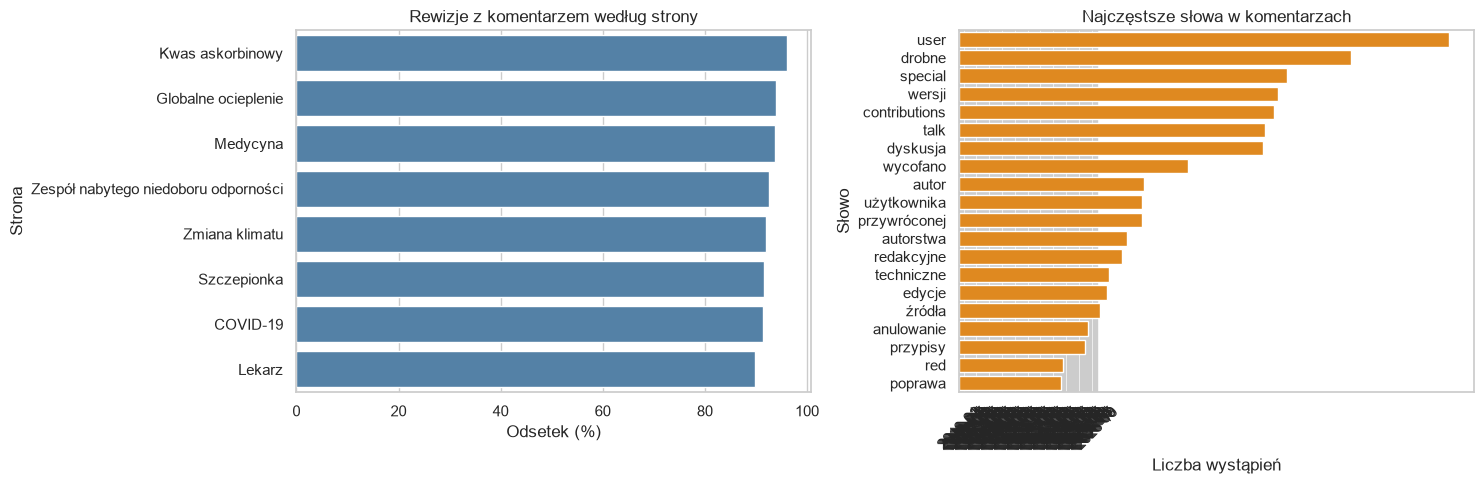

In [9]:
comment_timeline = (
    df.groupby("month", as_index=False)
      .agg(revisions=("revision_number", "size"), comments=("has_comment", "sum"))
)
comment_timeline["comment_rate"] = (
    100 * comment_timeline["comments"] / comment_timeline["revisions"]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=comment_by_page, y="page", x="comment_rate", ax=axes[0], color="steelblue")
axes[0].set(title="Rewizje z komentarzem według strony", xlabel="Odsetek (%)", ylabel="Strona")
sns.lineplot(data=comment_timeline, x="month", y="comment_rate", marker="o", ax=axes[1])
axes[1].tick_params(axis="x", rotation=45)
axes[1].set(title="Odsetek komentarzy w czasie", xlabel="Miesiąc", ylabel="Odsetek (%)")
plt.tight_layout()

stopwords = {
    "i", "a", "o", "w", "z", "na", "do", "ze", "że", "to", "jest", "oraz",
    "dla", "nie", "się", "po", "od", "jak", "by", "lub", "the", "of", "and",
}
tokens = (
    df.loc[df["has_comment"], "comment"]
      .str.lower()
      .str.findall(r"[a-ząćęłńóśźż]{3,}")
      .explode()
      .dropna()
)
top_comment_words = (
    tokens[~tokens.isin(stopwords)]
    .value_counts()
    .head(20)
    .rename_axis("słowo")
    .reset_index(name="liczba")
)
display(top_comment_words)
if not top_comment_words.empty:
    sns.barplot(data=top_comment_words, y="słowo", x="liczba", color="darkorange")
    plt.title("Najczęstsze słowa w komentarzach")
    plt.xlabel("Liczba wystąpień")
    plt.ylabel("Słowo")
    plt.tight_layout()
else:
    print("Brak komentarzy w danych. Pobierz dane ponownie po aktualizacji scrapera.")

## Odniesienia i źródła przywoływane w komentarzach

Z komentarzy wyciągamy zewnętrzne adresy URL oraz skróty stron/projektów Wikipedii, np. `[[WP:SK]]`, `[[WPT:...]]` i `[[WT:...]]`. Domeny URL-i pokazują, do jakich serwisów prowadzą odniesienia. Skróty Wikipedii są raportowane osobno, ponieważ nie są źródłami zewnętrznymi.

In [10]:
from urllib.parse import urlsplit

url_pattern = re.compile(r"https?://[^\s\]})>,]+", flags=re.IGNORECASE)
wiki_reference_pattern = re.compile(
    r"\[\[(?P<namespace>WP|WPT|WT):(?P<title>[^\]|]+)(?:\|[^\]]*)?\]\]",
    flags=re.IGNORECASE,
)

references = []
comment_mask = df["comment"].fillna("").astype(str).str.strip().ne("")
for row in df.loc[comment_mask].itertuples(index=False):
    for match in url_pattern.finditer(row.comment):
        raw_url = match.group(0).rstrip(".,;:!?\"")
        references.append({
            "page": row.page,
            "revision_number": row.revision_number,
            "introduced": row.introduced,
            "comment": row.comment,
            "reference_type": "external_url",
            "reference": raw_url,
            "domain": urlsplit(raw_url).netloc.lower().removeprefix("www."),
        })
    for match in wiki_reference_pattern.finditer(row.comment):
        namespace = match.group("namespace").upper()
        title = match.group("title").strip()
        references.append({
            "page": row.page,
            "revision_number": row.revision_number,
            "introduced": row.introduced,
            "comment": row.comment,
            "reference_type": f"wikipedia_{namespace.lower()}",
            "reference": f"{namespace}:{title}",
            "domain": "wikipedia.org",
        })

references_df = pd.DataFrame(references, columns=[
    "page", "revision_number", "introduced", "comment",
    "reference_type", "reference", "domain",
])
reference_quality = pd.Series({
    "komentarze przeanalizowane": int(df["has_comment"].sum()),
    "komentarze z odniesieniem": int(references_df[["page", "revision_number"]].drop_duplicates().shape[0]) if not references_df.empty else 0,
    "wystąpienia odniesień": len(references_df),
    "unikalne odniesienia": references_df["reference"].nunique(),
})
display(reference_quality.to_frame("wartość"))
display(references_df.head(20))

,wartość
komentarze przeanalizowane,2047
komentarze z odniesieniem,170
wystąpienia odniesień,285
unikalne odniesienia,38


,page,revision_number,introduced,comment,reference_type,reference,domain
0,COVID-19,3,2020-02-12 14:52:23+00:00,"[[WP:SK]], drobne techniczne",wikipedia_wp,WP:SK,wikipedia.org
1,COVID-19,59,2020-02-25 10:51:09+00:00,"Usunięto kategorię ""Koronawirusy""; Dodano kategorię ""Choroby wirusowe"" za pomocą [[WP:Narzędzia/HotCat|HotCat]]",wikipedia_wp,WP:Narzędzia/HotCat,wikipedia.org
2,COVID-19,110,2020-03-04 20:28:28+00:00,"[[WP:Narzędzia/disFixer|poprawa ujedn.]], [[WP:SK]]+[[WP:SK/ToS|ToS]]+[[WP:SK/mSI|mSI]], drobne techniczne",wikipedia_wp,WP:Narzędzia/disFixer,wikipedia.org
3,COVID-19,110,2020-03-04 20:28:28+00:00,"[[WP:Narzędzia/disFixer|poprawa ujedn.]], [[WP:SK]]+[[WP:SK/ToS|ToS]]+[[WP:SK/mSI|mSI]], drobne techniczne",wikipedia_wp,WP:SK,wikipedia.org
4,COVID-19,110,2020-03-04 20:28:28+00:00,"[[WP:Narzędzia/disFixer|poprawa ujedn.]], [[WP:SK]]+[[WP:SK/ToS|ToS]]+[[WP:SK/mSI|mSI]], drobne techniczne",wikipedia_wp,WP:SK/ToS,wikipedia.org
5,COVID-19,110,2020-03-04 20:28:28+00:00,"[[WP:Narzędzia/disFixer|poprawa ujedn.]], [[WP:SK]]+[[WP:SK/ToS|ToS]]+[[WP:SK/mSI|mSI]], drobne techniczne",wikipedia_wp,WP:SK/mSI,wikipedia.org
6,COVID-19,123,2020-03-05 21:29:46+00:00,[[:en:WP:CLEANER|WPCleaner]] v2.02 - Popr. błędy z [[WP:CHECK]] (Błędna składnia znacznika nowej linii - Przypis po ...,wikipedia_wp,WP:CHECK,wikipedia.org
7,COVID-19,137,2020-03-07 01:16:26+00:00,"drobne techniczne, [[WP:SK]]",wikipedia_wp,WP:SK,wikipedia.org
8,COVID-19,163,2020-03-09 10:05:21+00:00,"[[WP:SK]], drobne techniczne",wikipedia_wp,WP:SK,wikipedia.org
9,COVID-19,164,2020-03-09 10:06:01+00:00,"[[WP:SK]], drobne techniczne Kategoria:Szablon cytowania odrzucił URL",wikipedia_wp,WP:SK,wikipedia.org


,reference_type,occurrences,unique_references
1,wikipedia_wp,274,28
0,external_url,11,10


,domain,occurrences,unique_urls
1,aids.gov.pl,2,1
3,ecdc.europa.eu,2,2
5,sjp.pwn.pl,2,2
0,academia.edu,1,1
2,dbc.wroc.pl,1,1
4,gazetawroclawska.pl,1,1
6,who.int,1,1
7,wwf.pl,1,1


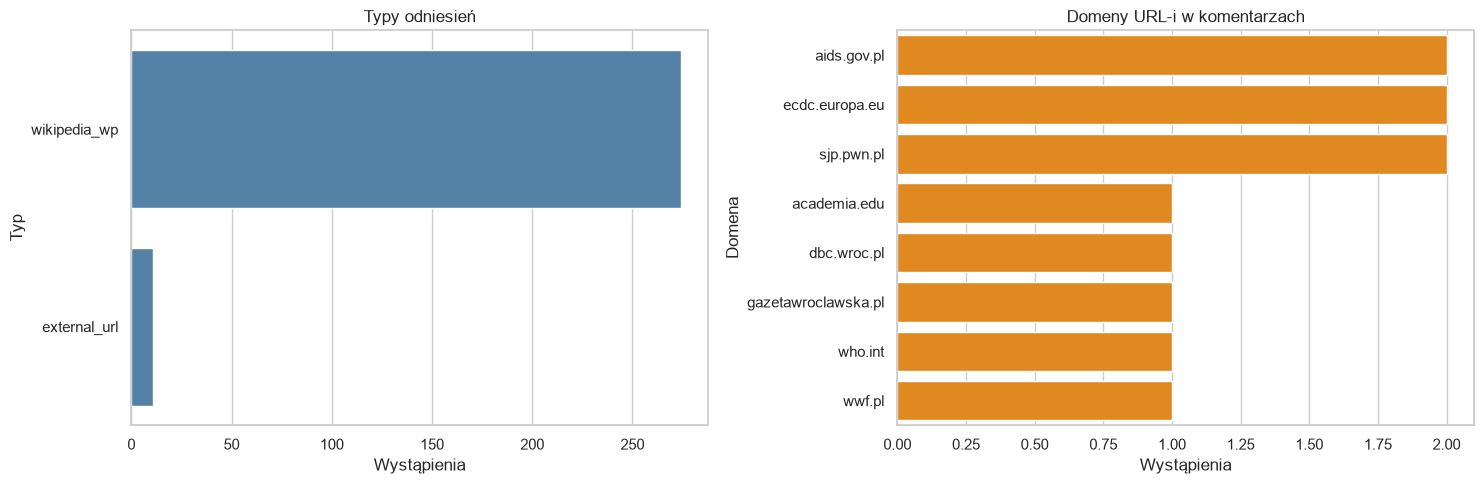

In [11]:
if not references_df.empty:
    reference_type_summary = (
        references_df.groupby("reference_type", as_index=False)
        .agg(occurrences=("reference", "size"), unique_references=("reference", "nunique"))
        .sort_values("occurrences", ascending=False)
    )
    domain_summary = (
        references_df[references_df["reference_type"] == "external_url"]
        .groupby("domain", as_index=False)
        .agg(occurrences=("reference", "size"), unique_urls=("reference", "nunique"))
        .sort_values("occurrences", ascending=False)
    )
    display(reference_type_summary)
    display(domain_summary)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.barplot(data=reference_type_summary, y="reference_type", x="occurrences", ax=axes[0], color="steelblue")
    axes[0].set(title="Typy odniesień", xlabel="Wystąpienia", ylabel="Typ")
    if not domain_summary.empty:
        sns.barplot(data=domain_summary.head(15), y="domain", x="occurrences", ax=axes[1], color="darkorange")
    axes[1].set(title="Domeny URL-i w komentarzach", xlabel="Wystąpienia", ylabel="Domena")
    plt.tight_layout()
else:
    print("Nie znaleziono URL-i ani skrótów WP/WPT/WT w komentarzach.")

## Codebook v2.0

Jeden codebook dla Reddita i Wikipedii zastępuje dwa niezgodne schematy kategorii instrumentu v1. Kategorie i ich angielskie kody pochodzą ze slajdu „Codebook”: `scientific`, `institutional`, `media`, `personal`, `social_blog`, `encyclopedia`, `other`, `unknown` i `none` (brak powołania). Źródłem prawdy jest `codebook/codebook.yaml`, a czytelną wersję dla annotatorów (`codebook/codebook.md`) generuje `make codebook`. Annotator wypełnia tylko `source_types`, a `cites_source` wynika z niego (0 przy `none`; reguła R13). Dla Wikipedii kodujemy dodatkowo `edit_about_sources`, bo znacznik „źródła/przypisy” opisuje rodzaj edycji, a nie powołanie się na źródło (reguła R10).

In [12]:
from digital_media_analysis.codebook import load_codebook

codebook = load_codebook()
print(f"Codebook v{codebook.version} z {codebook.date}: {codebook.status}")
with pd.option_context("display.max_colwidth", 200):
    display(codebook.variables_frame("wikipedia"))
    display(codebook.categories_frame()[["kod", "nazwa", "definicja", "wykluczamy"]])
    display(codebook.rules_frame())

Codebook v2.1 z 2026-10-24: wersja robocza przed pilotażem annotacji


,zmienna,nazwa,typ,pytanie
0,source_types,Typy źródeł,multilabel,"Jakiego typu źródła przywołuje autor? Zaznacz wszystkie występujące albo wpisz `none`, gdy jednostka nie zawiera powołania."
1,cites_source,Powołanie się na źródło,binary,"Czy autor wskazuje, skąd pochodzi informacja lub na czym opiera twierdzenie?"
2,edit_about_sources,Edycja dotyczy źródeł lub przypisów,binary,"Czy opis zmiany deklaruje dodanie, usunięcie, wymianę lub poprawę źródeł albo przypisów?"


,kod,nazwa,definicja,wykluczamy
0,scientific,Publikacje naukowe,"Konkretne publikacje naukowe: artykuły w czasopismach, preprinty, monografie, podręczniki akademickie i raporty badawcze (np. Nature, PubMed, Science).","instytucja naukowa lub statystyczna bez wskazania publikacji („dane GUS”, „według WHO”; wtedy `institutional`); własne badanie autora, np. rekrutacja do ankiety (R8); osobista wizyta u lekarza (wt..."
1,institutional,Instytucje naukowe i statystyczne,"Instytucje, które wytwarzają lub udostępniają wiedzę naukową, dane statystyczne i zalecenia zdrowotne, gdy źródłem jest instytucja, a nie konkretna publikacja: urzędy statystyczne (GUS, Eurostat),...","urzędy i administracja publiczna, ministerstwa, samorządy, policja, sądy, parlament i akty prawne (wtedy `other`); konkretna publikacja naukowa (wtedy `scientific`); instytucja jako uczestnik zdar..."
2,media,Media informacyjne,"Portale, gazety, telewizja, radio, agencje prasowe i magazyny publicystyczne (np. BBC, Reuters, Onet, WP).",media jako temat lub uczestnik zdarzenia („TVP zwolniła dziennikarza”); konto redakcji w serwisie społecznościowym bez linku do materiału redakcji (wtedy `social_blog`); blog prywatny lub na platf...
3,personal,Doświadczenia własne,"Autor opiera twierdzenie na własnym doświadczeniu albo na relacji konkretnej osoby z otoczenia, w tym specjalisty spotkanego osobiście („Z własnego doświadczenia powiem, że…”).","opis sytuacji bez funkcji dowodu („mieszkam w centrum, można odebrać”); osoby jako uczestnicy, np. szukanie znajomych czy prezent dla znajomego; własna opinia („według mnie”, „moim zdaniem”; R8)"
4,social_blog,"Media społecznościowe, blogi","Serwisy społecznościowe i platformy treści użytkowników (Reddit, YouTube, Facebook, X/Twitter, TikTok, Instagram, Wykop, fora) oraz blogi, w tym prywatne i hobbystyczne.","zdjęcia i filmy autora hostowane przez platformę (i.redd.it, preview.redd.it, v.redd.it, imgur; R3); nazwa serwisu w innym znaczeniu, np. kod rabatowy „reddit100”; blog redakcji medium informacyjn..."
5,encyclopedia,"Encyklopedie, słowniki","Encyklopedie (w tym artykuły Wikipedii i Britannica), słowniki (np. Słownik Języka Polskiego, sjp.pl), poradnie językowe słowników i bazy wiedzy.","skróty zasad i narzędzi Wikipedii w opisach edycji (`[[WP:SK]]`, `[[WP:POP]]`, `[[Pomoc:…]]`; R9)"
6,other,Inne źródła,"Źródło dające się zidentyfikować (nazwa lub link), które nie pasuje do pozostałych kategorii: sklepy, producenci i strony firm, urzędy i administracja publiczna (ministerstwa, samorządy, policja, ...","źródło pasujące do innej kategorii; `other` stosujemy tylko w ostateczności (R7); serwis lub strona jako miejsce poszukiwań albo przedmiot rozmowy (R2); reklama, link afiliacyjny, spam, kod rabato..."
7,unknown,Nieokreślone,"Autor odwołuje się do źródła, którego nie da się zidentyfikować („Badania pokazują, że…”, „czytałem gdzieś”, „według ekspertów”, „wg źródła”).","sam znacznik „źródła/przypisy” lub „dodano przypis” w opisie edycji (to `edit_about_sources`; R10); słowo „link” lub „artykuł” w innym znaczeniu („podeślijcie link partnerkom”, „poprawiam link”); ..."
8,none,Brak,"Brak odwołania do źródła: jednostka nie zawiera żadnego powołania zgodnego z definicją konstruktu i regułami. Kod `none` wpisujemy sam, bez innych kodów (R13).","jakiekolwiek rozpoznane powołanie, także ogólnikowe (wtedy jego kategoria albo `unknown`)"


,reguła,treść
0,R1,"Etykietujemy całą jednostkę: post (tytuł, treść i link) albo opis zmiany. Przy `source_types` zaznacz każdą kategorię, która wystąpiła choć raz; liczba wystąpień nie ma znaczenia."
1,R2,"Powołanie wymaga funkcji źródła: tekst lub link musi wskazywać, skąd pochodzi informacja, albo podawać ją jako podstawę twierdzenia. Sama wzmianka o instytucji, osobie lub serwisie jako uczestniku..."
2,R3,"Nie są źródłem: własne zdjęcia i filmy hostowane przez platformę (i.redd.it, preview.redd.it, v.redd.it, imgur), formularze ankiet, reklamy, linki afiliacyjne, spam, kody rabatowe i linki do profi..."
3,R4,"Kategorię wyznacza wydawca lub kanał, z którego pochodzi informacja, a nie temat ani osoby opisane w materiale. Artykuł wp.pl o decyzji ministerstwa to `media`. Gdy autor wymienia też źródło pierw..."
4,R5,"Konkret wygrywa z ogólnikiem. `unknown` zaznaczamy tylko wtedy, gdy jakieś odwołanie w jednostce pozostaje nierozpoznawalne. Jeśli ten sam fragment wskazuje konkretne źródło, kodujemy jego kategorię."
5,R6,"Nie oceniamy wiarygodności. Tekst pseudonaukowy w repozytorium publikacji to nadal `scientific`, a artykuł z portalu o niskiej wiarygodności to nadal `media`."
6,R7,"Kategoria `other` jest ostatecznością. Gdy domena jest nieznana, można sprawdzić, kto ją prowadzi, ale nie kodujemy treści strony docelowej."
7,R8,"Nie są powołaniem: własna opinia („według mnie”, „moim zdaniem”), prośba o źródło („macie jakieś dane?”) ani własne badanie autora (rekrutacja do ankiety)."
8,R9,"Wikipedia, elementy techniczne. Pomijamy automatyczny prefiks sekcji `/* … */`. Skróty zasad i narzędzi (`[[WP:…]]`, `[[Pomoc:…]]`), opisy redakcyjne („drobne redakcyjne”, „int.”, „kat.”), komunik..."
9,R10,"Wikipedia, praca nad przypisami. Deklaracja pracy nad źródłami (znacznik „źródła/przypisy”, „dodano przypis”, poprawa przypisów) daje `edit_about_sources = 1`. Kategorię źródła zamiast `none` daje..."


## Instrument v1: klasyfikacja źródeł i sposobu powołania

Bazowa ekstrakcja wykrywała adresy URL oraz skróty Wikipedii. Poniższy lokalny model hybrydowy dodaje klasyfikację domen i nazw instytucji, sygnały językowe (np. „według”, „źródło”, „badania”) oraz fragment kontekstu. `confidence` jest oceną heurystyczną dopasowania, a nie prawdopodobieństwem modelu. Warto pamiętać, że w tym zbiorze `comment` oznacza komentarz edycji Wikipedii, a nie komentarz dyskusyjny użytkownika.

Kod modelu przeniesiono bez zmian do `src/digital_media_analysis/instruments/rules_v1.py` i zamrożono jako punkt odniesienia dla walidacji. Daje te same wyniki co wersja, która wcześniej była wklejona w tę komórkę. Poprawki trafią do kolejnej wersji instrumentu, a nie do v1.

In [13]:
from digital_media_analysis.instruments import rules_v1

semantic_references_df = rules_v1.extract_wikipedia_references(df)
if semantic_references_df.empty:
    print("Nie wykryto odniesień możliwych do sklasyfikowania.")
else:
    semantic_quality = pd.Series({
        "komentarze z odniesieniem": semantic_references_df[["page", "revision_number"]].drop_duplicates().shape[0],
        "wystąpienia po deduplikacji": len(semantic_references_df),
        "unikalne źródła": semantic_references_df["reference"].nunique(),
        "średnia pewność": semantic_references_df["confidence"].mean(),
    })
    display(semantic_quality.to_frame("wartość").round(2))
    display(semantic_references_df.head(20))

,wartość
komentarze z odniesieniem,370.00
wystąpienia po deduplikacji,485.00
unikalne źródła,39.00
średnia pewność,0.76


,page,revision_number,comment,reference,domain,source_category,confidence,cue
0,COVID-19,3,"[[WP:SK]], drobne techniczne",WP:SK,wikipedia.org,źródła encyklopedyczne,0.90,
1,COVID-19,6,"drobne redakcyjne, [[Pomoc:Słowniczek#W|wikizacja]], drobne techniczne, źródła/przypisy",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła
2,COVID-19,8,"drobne redakcyjne, źródła/przypisy, int.",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła
3,COVID-19,11,"akt., drobne redakcyjne, źródła/przypisy",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła
4,COVID-19,12,"drobne redakcyjne, akt., źródła/przypisy",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła
5,COVID-19,14,"drobne redakcyjne, źródła/przypisy",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła
6,COVID-19,17,MalarzBOT: WPCHECK#64: poprawiam link tożsamy z tekstem linka,niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,link
7,COVID-19,20,"akt., drobne redakcyjne, źródła/przypisy, [[Pomoc:Słowniczek#W|wikizacja]], int., ilustracja, infobox, korekta",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła
8,COVID-19,22,"akt., źródła/przypisy",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła
9,COVID-19,23,"akt., źródła/przypisy",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła


,odniesienia,unikalne_źródła,komentarze,średnia_pewność
source_category,,,,
źródła encyklopedyczne,271,28,156,0.90
powołanie bez wskazanego źródła,197,1,197,0.55
instytucje publiczne,6,5,6,0.90
nauka i edukacja,4,4,4,0.90
media,4,4,4,0.90
organizacje społeczne i środowiskowe,2,2,2,0.90
inna domena zewnętrzna,1,1,1,0.80


,source_category,domain,odniesienia
10,źródła encyklopedyczne,wikipedia.org,271
2,instytucje publiczne,ecdc.europa.eu,2
1,instytucje publiczne,aids.gov.pl,2
7,nauka i edukacja,sjp.pwn.pl,2
5,media,wikipedia.org,2
0,inna domena zewnętrzna,dbc.wroc.pl,1
3,instytucje publiczne,who.int,1
6,nauka i edukacja,academia.edu,1
4,media,gazetawroclawska.pl,1
8,nauka i edukacja,wikipedia.org,1


,page,source_category,odniesienia
4,COVID-19,źródła encyklopedyczne,84
3,COVID-19,powołanie bez wskazanego źródła,83
12,Kwas askorbinowy,źródła encyklopedyczne,45
26,Zespół nabytego niedoboru odporności,źródła encyklopedyczne,39
10,Globalne ocieplenie,źródła encyklopedyczne,31
21,Szczepionka,źródła encyklopedyczne,28
11,Kwas askorbinowy,powołanie bez wskazanego źródła,25
9,Globalne ocieplenie,powołanie bez wskazanego źródła,24
14,Lekarz,powołanie bez wskazanego źródła,24
20,Szczepionka,powołanie bez wskazanego źródła,24


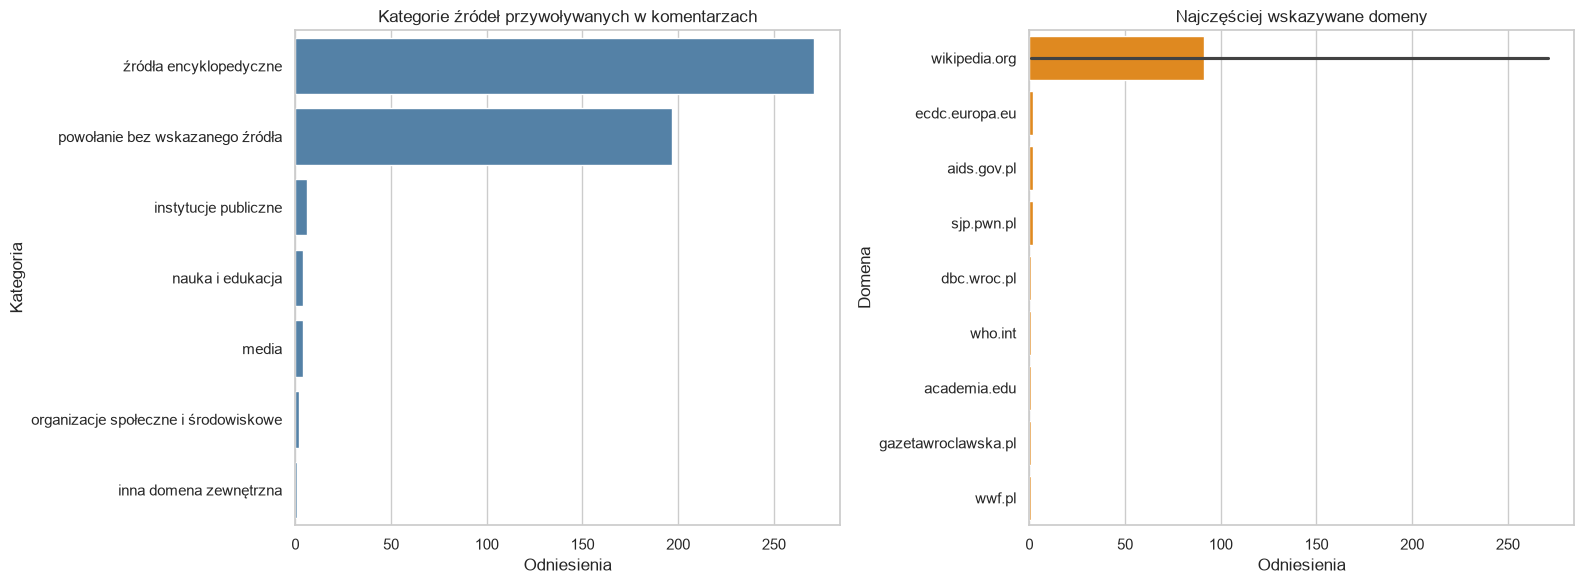

,page,source_category,reference,cue,comment
0,Zmiana klimatu,źródła encyklopedyczne,WP:SK/mSI,,[[WP:SK]]+[[WP:SK/mSI|mSI.v2]]+[[WP:SK/Bn|Bn]]
1,Zespół nabytego niedoboru odporności,nauka i edukacja,https://sjp.pwn.pl/poradnia/haslo/wiodacy;1424.html,,Brzydki rusycyzm https://sjp.pwn.pl/poradnia/haslo/wiodacy;1424.html
2,Zespół nabytego niedoboru odporności,media,https://gazetawroclawska.pl/jan-miodek-pelny-pelny-pelny/ar/704241,,"/* Cykl replikacyjny wirusa HIV */ jęz. poprawa błędu gramatycznego, por. np. https://gazetawroclawska.pl/jan-miode..."
3,Zespół nabytego niedoboru odporności,instytucje publiczne,https://www.aids.gov.pl/kampanie/CWL/01.html,,Poprawa błędu merytorycznego!!!\nZespół nabytego upośledzenia odporności (czyli AIDS) to nie to samo co zakażenie HI...
4,COVID-19,organizacje społeczne i środowiskowe,niesprecyzowane źródło,źródła,"/* Kontrowersje */ Great Barringon Declaration itp., odpowiedź w ""The Lancet"", zwiększone ryzyko zarażenia w rodzina..."
5,Medycyna,inna domena zewnętrzna,https://dbc.wroc.pl/Content/2026/PDF/wprowadzenie_do_medycyny.pdf,Link,"/* Nauki podstawowe medycyny */ Cytując z publikacji wprowadzenie do medycyny ""Medycynę zalicza się do nauk przyrodn..."
6,COVID-19,powołanie bez wskazanego źródła,niesprecyzowane źródło,źródła,"drobne redakcyjne, [[Pomoc:Słowniczek#W|wikizacja]], drobne techniczne, źródła/przypisy"


In [14]:
if not semantic_references_df.empty:
    # A comment is one revision of one page: revision numbers repeat across pages (bug #10).
    semantic_references_df = semantic_references_df.assign(
        comment_id=semantic_references_df["page"] + "#" + semantic_references_df["revision_number"].astype(str)
    )
    source_category_summary = (
        semantic_references_df.groupby("source_category")
        .agg(odniesienia=("reference", "size"), unikalne_źródła=("reference", "nunique"), komentarze=("comment_id", "nunique"), średnia_pewność=("confidence", "mean"))
        .sort_values("odniesienia", ascending=False)
    )
    source_by_page = (
        semantic_references_df.groupby(["page", "source_category"])
        .size().rename("odniesienia").reset_index()
        .sort_values("odniesienia", ascending=False)
    )
    top_sources = (
        semantic_references_df[semantic_references_df["domain"].ne("")]
        .groupby(["source_category", "domain"]).size().rename("odniesienia").reset_index()
        .sort_values("odniesienia", ascending=False).head(25)
    )
    display(source_category_summary.round(2))
    display(top_sources)
    display(source_by_page.head(30))

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    sns.barplot(data=source_category_summary.reset_index(), y="source_category", x="odniesienia", ax=axes[0], color="steelblue")
    axes[0].set(title="Kategorie źródeł przywoływanych w komentarzach", xlabel="Odniesienia", ylabel="Kategoria")
    if not top_sources.empty:
        sns.barplot(data=top_sources.head(15), y="domain", x="odniesienia", ax=axes[1], color="darkorange")
    axes[1].set(title="Najczęściej wskazywane domeny", xlabel="Odniesienia", ylabel="Domena")
    plt.tight_layout()
    plt.show()

    examples = semantic_references_df.sort_values("confidence", ascending=False).drop_duplicates("source_category")
    display(examples[["page", "source_category", "reference", "cue", "comment"]].reset_index(drop=True))
else:
    print("Brak wyników do agregacji.")

### Instrument v1 w kategoriach codebooka

Kategorie v1 są mapowane na kody codebooka, a wzmianki zwijane do etykiet na poziomie opisu zmiany (`cites_source`, `source_types`). Jednostkami są wszystkie rewizje z niepustym komentarzem; opis bez powołań dostaje `none`. v1 nie mierzy `edit_about_sources`.

Dwie rozbieżności z codebookiem widać bez annotacji. Skróty zasad i narzędzi (`WP:…`) v1 uznaje za źródła encyklopedyczne, a codebook nie uznaje ich za źródła (reguła R9). Sam znacznik „źródła/przypisy” v1 traktuje jako ogólnikowe powołanie, a codebook jako `edit_about_sources` (reguła R10).

In [15]:
from digital_media_analysis.codebook import NO_SOURCE
from digital_media_analysis.instruments.labels import UNTYPED_SOURCE, to_document_labels

display(pd.DataFrame(
    {"kategoria v1": category, "kod codebooka": code or f"({UNTYPED_SOURCE}, gdy brak innego typu)"}
    for category, code in rules_v1.WIKIPEDIA_CATEGORY_MAP.items()
))

commented = df[df["has_comment"]]
v1_labels = to_document_labels(
    semantic_references_df,
    commented,
    unit_columns=["page", "revision_number"],
    category_column="source_category",
    category_map=rules_v1.WIKIPEDIA_CATEGORY_MAP,
    non_citation=rules_v1.WIKIPEDIA_NON_CITATION,
)
detectable = set(rules_v1.WIKIPEDIA_CATEGORY_MAP.values()) | {NO_SOURCE}
coverage = (
    v1_labels["source_types"].str.split(";").explode()
    .loc[lambda codes: codes.ne("")]
    .value_counts()
    .reindex(codebook.category_codes, fill_value=0)
    .rename_axis("kod")
    .to_frame("opisy zmian wg v1")
)
coverage["v1 ma regułę"] = coverage.index.isin(detectable)
print(f"Opisy zmian z powołaniem wg v1: {v1_labels['cites_source'].sum()} / {len(v1_labels)}")
display(coverage)

shortcut_as_source = (
    semantic_references_df["reference"].str.match(r"(WP|WPT|WT):")
    & semantic_references_df["source_category"].ne("odniesienie techniczne Wikipedii")
)
tag_only = (
    semantic_references_df["reference"].eq("niesprecyzowane źródło")
    & semantic_references_df["comment"].str.contains("źródła/przypisy", regex=False)
)
display(pd.Series({
    "skróty WP:… liczone jako źródło (R9)": int(shortcut_as_source.sum()),
    "wzmianki bez źródła w opisach ze znacznikiem „źródła/przypisy” (R10)": int(tag_only.sum()),
    "wszystkie wzmianki v1": len(semantic_references_df),
}).to_frame("wzmianki"))

,kategoria v1,kod codebooka
0,instytucje publiczne,institutional
1,nauka i edukacja,scientific
2,media,media
3,organizacje społeczne i środowiskowe,other
4,źródła encyklopedyczne,encyclopedia
5,źródła osobiste,personal
6,inna domena zewnętrzna,other
7,powołanie bez wskazanego źródła,unknown


Opisy zmian z powołaniem wg v1: 370 / 2047


,opisy zmian wg v1,v1 ma regułę
kod,,
scientific,4,True
institutional,6,True
media,4,True
personal,0,True
social_blog,0,False
encyclopedia,156,True
other,3,True
unknown,197,True
none,1677,True


,wzmianki
skróty WP:… liczone jako źródło (R9),274
wzmianki bez źródła w opisach ze znacznikiem „źródła/przypisy” (R10),88
wszystkie wzmianki v1,485


## Gold standard: próba do annotacji

Próbę losuje `make gold-sample` (`src/digital_media_analysis/gold.py`; ziarno, parametry i przydział lat w `annotations/sample_design.json`). Arkusze dla annotatorów eksportuje `make pilot-sheets`, a pełne dane wylosowanych jednostek zapisuje `make sample-csv` do `data_samples/` (w gicie). Manifest `annotations/sample_manifest.csv` zawiera tylko identyfikatory, rok, warstwy i wagi. Tekst trafia wyłącznie do arkuszy (poza gitem) i do plików CSV w `data_samples/`.

Schemat losowania:

1. Rama: jednostki z okresu badania danej platformy (`study_periods` w `config.yaml`). Każda platforma ma własny okres, bo służy innej hipotezie.
2. Pilotaż: mała próba z każdego roku do kalibracji codebooka. Nie wchodzi do metryk ani do ramy losowania próby głównej.
3. Próba główna: losowanie warstwowe z pozostałych jednostek. Każda platforma ma razem 500 jednostek (z pilotażem), rozdzielonych między lata tak równo, jak pozwalają dane. Dzięki temu oszacowania dla poszczególnych lat mają podobną precyzję. Rok mniejszy od równego udziału wchodzi w całości (`whole_years` w `sample_design.json`).
4. Podział wewnątrz każdej warstwy na `dev` (strojenie reguł i promptu) i `test` (tylko końcowy pomiar). Waga testowa N_h / n_h odtwarza liczebność warstwy w ramie.

**Wikipedia, lata 2020–2026.** Hipoteza: w latach 2020–2026 użytkownicy częściej odwołują się do alternatywnych źródeł wiedzy (blogi, influencerzy, „eksperci niezależni”). Rama to rewizje z niepustym opisem zmiany od 1.01.2020 do 13.10.2026 (rok 2026 jest niepełny). Lata 2023, 2025 i 2026 mają mniej opisów niż równy udział, więc wchodzą w całości (72, 53 i 59), a pozostałe lata dają po 79 opisów, w tym po 3 do pilotażu (1 `cue`, 2 `other`).

Warstwy to rok × sygnał. Sygnał to szeroka cecha powierzchniowa opisu zmiany, niezależna od instrumentu: `link` (adres URL), `cue` (słowa o źródłach, przypisach, danych) albo `other`. W próbie głównej opisy z linkiem wchodzą w całości, `cue` do jednej trzeciej roku, a `other` dopełnia rok. Nadpróbkowanie `cue` i równy przydział lat koryguje waga. W tabeli sygnałów suma wag testu odtwarza liczebność ramy.

Skład stron też zmienia się w czasie: w 2020 r. większość opisów pochodzi ze strony COVID-19. Trzecia tabela pokazuje ten skład.

In [16]:
from digital_media_analysis import gold
from digital_media_analysis.config_reader import get_study_period

try:
    manifest = gold.load_manifest()
except FileNotFoundError as error:
    print(error)
else:
    wikipedia_sample = manifest[manifest["platform"].eq("wikipedia")]
    population = gold.in_study_period(
        gold.wikipedia_units(df[["page", "revision_number", "introduced", "comment"]]), *get_study_period("wikipedia")
    )
    signal_table = pd.concat(
        [
            population["signal"].value_counts().rename("populacja"),
            pd.crosstab(wikipedia_sample["signal"], wikipedia_sample["split"]).reindex(columns=["pilot", "dev", "test"]),
            wikipedia_sample[wikipedia_sample["split"].eq("test")].groupby("signal")["weight"].sum().rename("suma wag test"),
        ],
        axis=1,
    ).reindex(["link", "cue", "other"])
    display(gold.year_summary(manifest, "wikipedia"))
    display(signal_table.round(1))
    display(pd.crosstab(wikipedia_sample["year"], wikipedia_sample["group"], margins=True, margins_name="razem"))
    display(gold.design_summary(manifest, "wikipedia").round(2))

,N (rama),pilot,pilot2,dev,test
year,,,,,
2020,762,3,8,25,51
2021,264,3,8,24,52
2022,134,3,7,24,52
2023,72,3,0,22,47
2024,109,3,7,24,52
2025,53,3,0,15,35
2026,59,3,0,18,38


,populacja,pilot,dev,test,suma wag test
signal,,,,,
link,10,0,2,8,10.0
cue,334,7,42,94,327.0
other,1109,14,108,225,1095.0


group,COVID-19,Globalne ocieplenie,Kwas askorbinowy,Lekarz,Medycyna,Szczepionka,Zespół nabytego niedoboru odporności,Zmiana klimatu,razem
year,,,,,,,,,
2020,69,3,1,0,1,2,10,1,87
2021,47,11,1,6,3,6,10,3,87
2022,25,22,4,16,3,6,4,6,86
2023,9,23,0,14,4,10,9,3,72
2024,8,13,12,18,2,5,28,0,86
2025,5,14,7,8,1,4,14,0,53
2026,8,8,5,13,1,6,4,14,59
razem,171,94,30,75,15,39,79,27,530


,N_h (rama),dev,test,waga test
stratum,,,,
2020|cue,163,8,17,9.59
2020|link,3,1,2,1.50
2020|other,593,16,32,18.53
2021|cue,76,8,17,4.47
2021|link,5,1,4,1.25
2021|other,180,15,31,5.81
2022|cue,27,8,17,1.59
2022|link,1,0,1,1.00
2022|other,103,16,34,3.03


### Zgodność annotatorów w pilotażu

Po wypełnieniu arkuszy uruchom najpierw `make import-labels`. Ten krok sprawdza arkusze i zapisuje etykiety bez tekstu do `annotations/labels/pilot/`. Następnie `make agreement` zapisuje tabele i wykres do `annotations/agreement/`.

Poniżej te same miary dla Wikipedii:
- κ Cohena (dla dwóch osób) i α Krippendorffa: nominalna dla zmiennych 0/1, z odległością MASI dla całego zbioru typów źródeł;
- 95% przedziały bootstrap, z losowaniem jednostek ze zwracaniem;
- progi Krippendorffa: α ≥ 0,8 oznacza zgodność rzetelną, 0,667–0,8 pozwala tylko na wstępne wnioski.

Kategorii, które obie osoby razem zaznaczyły w mniej niż 5 jednostkach, nie oceniamy. W pilotażu dotyczy to większości typów źródeł, więc zgodność per kategoria rozstrzygnie dopiero próba główna. Niezgodności (z tekstem z danych lokalnych) to materiał na sesję uzgadniania i na slajd.

units  cites_share  mean_types_when_citing  \
platform  annotator                                               
wikipedia IS            20         0.15                     1.0   
          JP            51         0.04                     1.0   

                     uncertain_share  
platform  annotator                   
wikipedia IS                     0.0  
          JP                    0.12

,variable,units,annotators,positive_units,observed_agreement,prevalence,kappa,kappa_low,kappa_high,alpha,alpha_low,alpha_high,distance,verdict
0,cites_source,20,2,3,0.85,0.08,0.00,0.0,0.0,-0.05,-0.15,0.0,nominal,za mało przypadków
1,edit_about_sources,20,2,5,0.90,0.20,0.69,0.0,1.0,0.70,-0.03,1.0,nominal,tylko wstępne wnioski
2,source_types,20,2,3,0.85,NaN,NaN,NaN,NaN,-0.04,-0.12,0.0,MASI,za mało przypadków
3,source_types:scientific,20,2,0,1.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,nominal,za mało przypadków
4,source_types:institutional,20,2,0,1.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,nominal,za mało przypadków
5,source_types:media,20,2,0,1.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,nominal,za mało przypadków
6,source_types:personal,20,2,2,0.90,0.05,0.00,0.0,0.0,-0.03,-0.11,0.0,nominal,za mało przypadków
7,source_types:social_blog,20,2,0,1.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,nominal,za mało przypadków
8,source_types:encyclopedia,20,2,0,1.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,nominal,za mało przypadków
9,source_types:other,20,2,1,0.95,0.02,0.00,0.0,0.0,0.00,-0.05,0.0,nominal,za mało przypadków


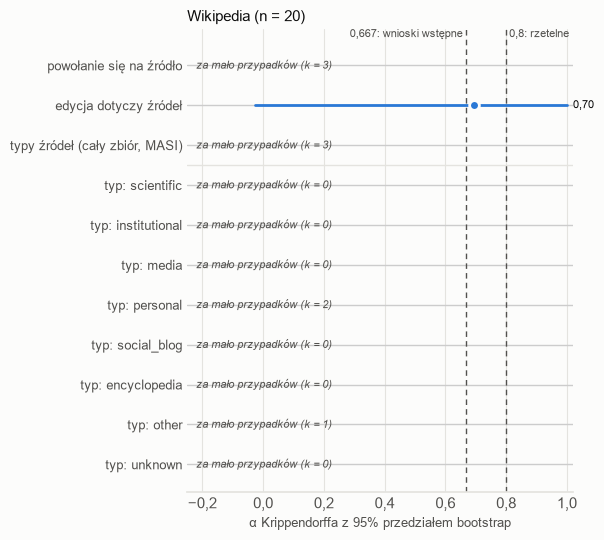

,unit_id,platform,variable,IS,JP,uncertain,comment
0,COVID-19#653,wikipedia,cites_source,1.0,0.0,,/* Objawy */ u niektórych pacjentów wyłącznie objawy żołądkowo-jelitowe (prawdopodobnie przez zanieczyszczenie fekal...
1,Globalne ocieplenie#257,wikipedia,cites_source,1.0,0.0,,Ściema
2,Lekarz#194,wikipedia,cites_source,1.0,0.0,,"liczba lek. wet., certyfikowane specjalizacje lek. wet., źródła/przypisy"
3,COVID-19#653,wikipedia,source_types,personal,none,,/* Objawy */ u niektórych pacjentów wyłącznie objawy żołądkowo-jelitowe (prawdopodobnie przez zanieczyszczenie fekal...
4,Globalne ocieplenie#257,wikipedia,source_types,personal,none,,Ściema
5,Lekarz#194,wikipedia,source_types,other,none,,"liczba lek. wet., certyfikowane specjalizacje lek. wet., źródła/przypisy"
6,Globalne ocieplenie#181,wikipedia,edit_about_sources,0.0,1.0,JP,ujednolicam zapis daty dostępu w szablonie cytowania
7,Globalne ocieplenie#257,wikipedia,edit_about_sources,1.0,0.0,,Ściema


In [17]:
from digital_media_analysis import agreement, annotations

pilot_labels = annotations.load_labels("pilot")
pilot_labels = pilot_labels[pilot_labels["platform"].eq("wikipedia")]
if pilot_labels["annotator"].nunique() < 2:
    print("Brak etykiet pilotażu od dwóch osób. Po annotacji uruchom `make import-labels`.")
else:
    pilot_agreement = agreement.agreement_table(pilot_labels, codebook.category_codes)
    display(agreement.annotator_summary(pilot_labels).round(2))
    display(pilot_agreement.drop(columns="platform").round(2))
    agreement.plot_alpha(pilot_agreement)
    plt.show()
    unit_texts = df.assign(unit_id=df["page"] + "#" + df["revision_number"].astype(str)).set_index("unit_id")[["comment"]]
    display(agreement.disagreements(pilot_labels).join(unit_texts, on="unit_id"))

## Walidacja instrumentów na gold

Pięć instrumentów etykietuje jednostki gold w kodach codebooka: v1 (reguły z tego notatnika, zamrożone), zero-shot NLI (`zeroshot_v1`, model mDeBERTa-v3 wielojęzyczny), GLiNER (`gliner_v1`, wydobywanie wzmianek o źródłach), reguły v2 z codebooka (`rules_v2`, budowane tylko na `dev`) i zmiana przypisów w treści rewizji (`refs_v1`, tylko `edit_about_sources` na Wikipedii). `rules_v2` i `refs_v1` nie przeszły jeszcze testu. `make tune` stroi próg i język hipotez na zbiorze `dev`, a `make validate SPLIT=test FROZEN=1` uruchamia zbiór testowy raz, po zamrożeniu instrumentów commitem. Metryki są ważone wagami próby (jednostki zakodowane w każdej warstwie), z przedziałami bootstrap; kategorie z mniej niż 10 przypadkami w gold są raportowane bez oceny. Wyniki osobno dla części IS i JP pokazują, czy instrument zgadza się bardziej z jedną osobą.

Poniżej wyniki z `annotations/validation/dev_metrics.csv` dla Wikipedii.

In [18]:
from digital_media_analysis.paths import VALIDATION_DIR

metrics_path = VALIDATION_DIR / "dev_metrics.csv"
if not metrics_path.exists():
    print("Brak wyników walidacji; uruchom `make tune` (wymaga `uv sync --group ml`).")
else:
    dev_metrics = pd.read_csv(metrics_path)
    platform_metrics = dev_metrics[dev_metrics["platform"].eq("wikipedia")]
    overall = platform_metrics[platform_metrics["subset"].eq("all")]
    headline = overall[
        overall["variable"].isin(["cites_source", "edit_about_sources", "source_types"])
        & overall["metric"].isin(["precision", "recall", "f1", "kappa", "masi", "macro_f1"])
    ]
    display(headline.pivot_table(index=["variable", "metric"], columns="instrument", values="value").round(3))
    intervals = headline[headline["metric"].isin(["f1", "masi"])].assign(
        przedział=lambda frame: frame["low"].round(2).astype(str) + "–" + frame["high"].round(2).astype(str)
    )
    display(intervals.pivot_table(index=["variable", "metric"], columns="instrument", values="przedział", aggfunc="first"))
    per_category = overall[overall["variable"].str.startswith("source_types:") & overall["metric"].eq("f1")]
    display(per_category.pivot_table(index=["variable", "support"], columns="instrument", values="value").round(2))
    by_annotator = platform_metrics[platform_metrics["variable"].eq("source_types") & platform_metrics["metric"].eq("masi")]
    display(by_annotator.pivot_table(index="subset", columns="instrument", values="value").round(3))

instrument                    gliner_v1  refs_v1  rules_v1  rules_v2  \
variable           metric                                              
cites_source       f1             0.122      NaN     0.221     0.315   
                   kappa          0.184      NaN     0.174     0.299   
                   precision      0.791      NaN     0.198     0.715   
                   recall         0.066      NaN     0.249     0.202   
edit_about_sources f1               NaN    0.573       NaN     0.799   
                   kappa            NaN    0.427       NaN     0.682   
                   precision        NaN    0.439       NaN     0.820   
                   recall           NaN    0.821       NaN     0.780   
source_types       masi           0.883      NaN     0.768     0.892   

instrument                    zeroshot_v1  
variable           metric                  
cites_source       f1               0.310  
                   kappa            0.024  
                   precision        0.220  
                   recall           0.525  
edit_about_sources f1               0.274  
                   kappa            0.048  
                   precision        0.180  
                   recall           0.574  
source_types       masi             0.658

,instrument,gliner_v1,refs_v1,rules_v1,rules_v2,zeroshot_v1
variable,metric,,,,,
cites_source,f1,0.06–0.24,NaN,0.12–0.35,0.1–0.59,0.09–0.5
edit_about_sources,f1,NaN,0.44–0.71,NaN,0.67–0.9,0.17–0.37
source_types,masi,0.81–0.94,NaN,0.69–0.84,0.82–0.95,0.56–0.76


,instrument,gliner_v1,rules_v1,rules_v2,zeroshot_v1
variable,support,,,,
source_types:encyclopedia,4,0.00,0.00,0.55,0.00
source_types:institutional,4,0.27,0.25,0.59,0.00
source_types:media,1,0.00,0.00,0.00,0.02
source_types:other,7,0.11,0.11,0.11,0.00
source_types:personal,5,0.00,0.00,0.00,0.00
source_types:social_blog,0,NaN,NaN,NaN,0.00
source_types:unknown,2,0.00,0.07,0.00,0.00


instrument,gliner_v1,rules_v1,rules_v2,zeroshot_v1
subset,,,,
IS,0.802,0.697,0.802,0.544
JP,0.949,0.824,0.964,0.750
all,0.883,0.768,0.892,0.658


### Gold standard: udziały ważone, bez instrumentu

Etykiety gold z `dev` i `test` razem, ważone N_h przez liczbę zakodowanych jednostek warstwy, z przedziałami bootstrap w warstwach (`make compare`, plik `annotations/validation/gold_shares.csv`). To pierwsza estymata udziałów źródeł na Wikipedii, która nie zależy od żadnego instrumentu. Etykiety IS i JP różnią się systematycznie (zob. walidację), więc estymata dziedziczy ten rozrzut.


In [19]:
shares_path = VALIDATION_DIR / "gold_shares.csv"
if not shares_path.exists():
    print("Brak pliku; uruchom `make compare`.")
else:
    gold_shares = pd.read_csv(shares_path)
    gold_shares = gold_shares[gold_shares["platform"].eq("wikipedia")].set_index("variable")
    display(gold_shares[["share", "low", "high", "positives", "units"]].round(3))


,share,low,high,positives,units
variable,,,,,
cites_source,0.134,0.087,0.187,43,294
scientific,0.004,0.000,0.013,1,294
institutional,0.022,0.005,0.042,7,294
media,0.003,0.000,0.006,2,294
personal,0.051,0.016,0.098,12,294
social_blog,0.000,0.000,0.000,0,294
encyclopedia,0.027,0.011,0.044,10,294
other,0.020,0.006,0.040,8,294
unknown,0.007,0.000,0.017,3,294


### Analiza błędów i błąd różnicowy (slajd 3)

`make errors` zapisuje każdy błąd instrumentów na `dev` z przyczyną zaproponowaną z zamkniętej listy (`annotations/errors/dev_errors.csv`, bez tekstu) oraz arkusz `annotations/sheets/errors_dev.xlsx` z tekstem, w którym człowiek potwierdza albo poprawia przyczynę (potem `make errors IMPORT=1`). Wykres Pareto liczy przyczyny potwierdzone, a do tego czasu proponowane. Przyczyny błędów `refs_v1` to zawsze „inne”: instrument czyta treść artykułu, a codebook deklarację w opisie zmiany.

Błąd różnicowy: odsetek fałszywych trafień (wśród jednostek bez powołania w gold) i pominięć (wśród jednostek z powołaniem) dla połówek okresu badania i dla stron, na zbiorze testowym. `p_permutation` sprawdza, czy liczby błędów różnią się między grupami (permutacja błędów między jednostkami).


instrument,gliner_v1,refs_v1,rules_v1,rules_v2
variable,,,,
cites_source,21,0,40,19
edit_about_sources,0,33,0,15
source_types:encyclopedia,1,0,3,0
source_types:institutional,0,0,2,0
source_types:media,0,0,1,0
source_types:other,0,0,2,1
source_types:personal,0,0,2,0
source_types:unknown,1,0,4,1


,instrument,cause,errors,confirmed,share,cumulative_share
0,gliner_v1,brak w słowniku,21,0,0.91,0.91
1,gliner_v1,brak kontekstu,1,0,0.04,0.96
2,gliner_v1,skrót WP:,1,0,0.04,1.00
3,refs_v1,inne,33,0,1.00,1.00
4,rules_v1,brak w słowniku,20,0,0.37,0.37
5,rules_v1,skrót WP:,18,0,0.33,0.70
6,rules_v1,znacznik edycji,8,0,0.15,0.85
7,rules_v1,brak kontekstu,7,0,0.13,0.98
8,rules_v1,podciąg,1,0,0.02,1.00
9,rules_v2,brak w słowniku,28,0,0.78,0.78


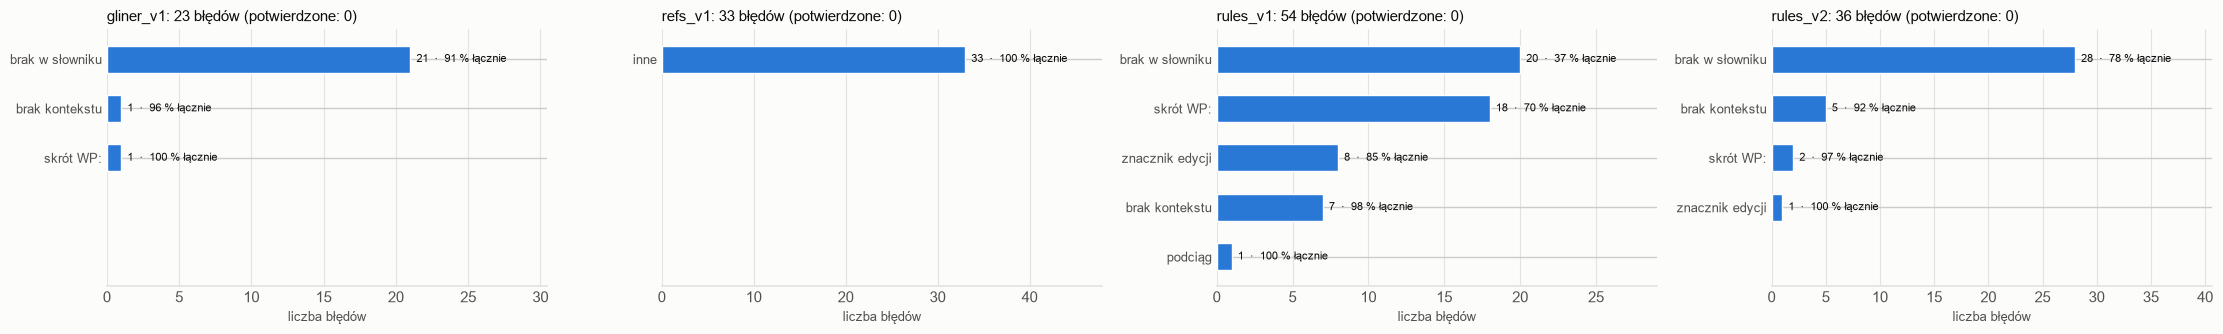

instrument                                                         gliner_v1  \
grouping group                                rate                             
period   2020–2022                            false_negative_rate       0.83   
                                              false_positive_rate       0.03   
         2023–2026                            false_negative_rate       0.74   
                                              false_positive_rate       0.05   
source   COVID-19                             false_negative_rate       0.75   
                                              false_positive_rate       0.03   
         Globalne ocieplenie                  false_negative_rate       0.94   
                                              false_positive_rate       0.00   
         Kwas askorbinowy                     false_positive_rate       0.06   
         Lekarz                               false_negative_rate       0.65   
                                              false_positive_rate       0.11   
         Medycyna                             false_positive_rate       0.00   
         Szczepionka                          false_negative_rate       1.00   
                                              false_positive_rate       0.00   
         Zespół nabytego niedoboru odporności false_negative_rate       0.65   
                                              false_positive_rate       0.02   
         Zmiana klimatu                       false_negative_rate       1.00   
                                              false_positive_rate       0.00   

instrument                                                         rules_v1  \
grouping group                                rate                            
period   2020–2022                            false_negative_rate      0.89   
                                              false_positive_rate      0.17   
         2023–2026                            false_negative_rate      0.96   
                                              false_positive_rate      0.24   
source   COVID-19                             false_negative_rate      1.00   
                                              false_positive_rate      0.25   
         Globalne ocieplenie                  false_negative_rate      0.94   
                                              false_positive_rate      0.13   
         Kwas askorbinowy                     false_positive_rate      0.55   
         Lekarz                               false_negative_rate      1.00   
                                              false_positive_rate      0.19   
         Medycyna                             false_positive_rate      0.21   
         Szczepionka                          false_negative_rate      1.00   
                                              false_positive_rate      0.00   
         Zespół nabytego niedoboru odporności false_negative_rate      0.65   
                                              false_positive_rate      0.04   
         Zmiana klimatu                       false_negative_rate      0.00   
                                              false_positive_rate      0.00   

instrument                                                         zeroshot_v1  
grouping group                                rate                              
period   2020–2022                            false_negative_rate         0.73  
                                              false_positive_rate         0.28  
         2023–2026                            false_negative_rate         0.74  
                                              false_positive_rate         0.34  
source   COVID-19                             false_negative_rate         0.86  
                                              false_positive_rate         0.30  
         Globalne ocieplenie                  false_negative_rate         1.00  
                                              false_positive_rate         0.31  
        

instrument                    gliner_v1  rules_v1  zeroshot_v1
grouping rate                                                 
period   false_negative_rate      1.000     0.610        1.000
         false_positive_rate      1.000     0.384        0.559
source   false_negative_rate      0.707     0.068        0.213
         false_positive_rate      0.823     0.015        0.669

In [20]:
from digital_media_analysis import errors
from digital_media_analysis.paths import ERRORS_DIR

errors_path = ERRORS_DIR / "dev_errors.csv"
if not errors_path.exists():
    print("Brak listy błędów; uruchom `make errors`.")
else:
    error_list = pd.read_csv(errors_path, dtype=str, keep_default_na=False)
    platform_errors = error_list[error_list["platform"].eq("wikipedia")]
    display(pd.crosstab(platform_errors["variable"], platform_errors["instrument"]))
    counted = errors.pareto(platform_errors)
    display(counted.round(2))
    if len(counted):
        errors.plot_pareto(counted)
        plt.show()

differential_path = ERRORS_DIR / "differential_test.csv"
if differential_path.exists():
    differential = pd.read_csv(differential_path)
    differential = differential[differential["platform"].eq("wikipedia") & differential["variable"].eq("cites_source")]
    display(differential.pivot_table(index=["grouping", "group", "rate"], columns="instrument", values="value").round(2))
    display(differential.drop_duplicates(["instrument", "grouping", "rate"])
            .pivot_table(index=["grouping", "rate"], columns="instrument", values="p_permutation").round(3))


### Porównanie instrumentów (slajd 4)

Z zapisanych predykcji na zbiorze testowym (`make compare`): κ instrumentów względem gold na tle κ annotatorów w pilotażu, dokładny test McNemara dla par instrumentów (`cites_source`) i τ Kendalla między rankingiem kategorii według instrumentu i według gold. Przy powołaniu u prawie wszystkich postów κ jest niskie mimo wysokiej zgodności (paradoks rozpowszechnienia), więc obok κ podajemy odsetek zgodności.


In [21]:
for name in ["comparison_kappa", "comparison_mcnemar", "comparison_rankings"]:
    path = VALIDATION_DIR / f"{name}.csv"
    if not path.exists():
        print(f"Brak {path.name}; uruchom `make compare`.")
        continue
    table = pd.read_csv(path)
    display(table[table["platform"].eq("wikipedia")].round(3))


,platform,variable,rater,kappa,low,high,units,agreement,prevalence
4,wikipedia,cites_source,annotators (pilot),0.000,0.000,0.000,20,0.850,0.075
5,wikipedia,cites_source,gliner_v1,0.267,0.123,0.454,147,0.858,NaN
6,wikipedia,cites_source,rules_v1,-0.028,-0.117,0.077,147,0.714,NaN
7,wikipedia,cites_source,zeroshot_v1,-0.010,-0.129,0.102,147,0.644,NaN
8,wikipedia,edit_about_sources,annotators (pilot),0.688,0.000,1.000,20,0.900,0.200
9,wikipedia,edit_about_sources,zeroshot_v1,0.132,0.064,0.207,147,0.479,NaN


,platform,first,second,units,only_first_right,only_second_right,both_right,both_wrong,p_exact
1,wikipedia,rules_v1,zeroshot_v1,147,29,21,72,25,0.322
3,wikipedia,rules_v1,gliner_v1,147,5,31,96,15,0.000
5,wikipedia,zeroshot_v1,gliner_v1,147,5,39,88,15,0.000


,platform,source,reference,categories,kendall_tau,p_value,same_top_category
3,wikipedia,gliner_v1,gold,8,0.181,0.564,False
4,wikipedia,rules_v1,gold,8,0.123,0.688,False
5,wikipedia,zeroshot_v1,gold,8,-0.539,0.073,False
